**420-C74-SF - Techniques d'apprentissage automatique - Automne 2026 - Spécialiste en solutions d'intelligence artificielle**<br/>
© 2026 MKL.AI - Tous droits réservés
<br/>
![Atelier - Regroupement hiérarchique (NCI60)](static/22-A-banner.png)
<br/>
**Objectif:** cette séance de travaux pratiques a pour objectif l'analyse de données génomiques (jeu de données NCI60). Les techniques mise en oeuvre seront l'ACP et le regroupement hiérarchique

In [1]:
%reload_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd

# Le reste des modules sera importé au fur et à mesure des exercices ...

In [3]:
import seaborn as sns; sns.set()
import matplotlib.pyplot as plt
# Configuration de la visualisation
sns.set(style="darkgrid")
sns.set_context("notebook", font_scale=1.5, rc={"lines.linewidth": 2.5})
plt.rcParams['figure.figsize']=(12,8)

## 1 - Lecture des données

Les méthodes d'apprentissage non supervisé comme l'ACP et le clustering sont très populaires en analyse des données génomiques. Ces méthodes seront illustrées sur le jeu de données de biopuces NCI60, qui
consiste en 6830 **mesures d'expression de gènes** sur 64 lignées de cellules cancéreuses.

**Exercice 1-1 - À l'aide de la librairie Pandas, lire le fichier de données `NCI60.csv`**

In [4]:
# Compléter cette cellule ~ 1 ligne de code

In [5]:
nci60 = pd.read_csv('../../data/NCI60.csv', index_col=[0])
nci60

,1,2,3,4,5,6,7,8,9,10,...,6821,6822,6823,6824,6825,6826,6827,6828,6829,6830
V1,0.300000,1.180000,0.550000,1.140000,-0.265000,-7.000000e-02,0.350000,-0.315000,-0.450000,-0.654980,...,-0.990020,0.000000,0.030000,-0.175000,0.629981,-0.030000,0.000000,0.280000,-0.340000,-1.930000
V2,0.679961,1.289961,0.169961,0.379961,0.464961,5.799610e-01,0.699961,0.724961,-0.040039,-0.285019,...,-0.270058,-0.300039,-0.250039,-0.535039,0.109941,-0.860039,-1.250049,-0.770039,-0.390039,-2.000039
V3,0.940000,-0.040000,-0.170000,-0.040000,-0.605000,0.000000e+00,0.090000,0.645000,0.430000,0.475019,...,0.319981,0.120000,-0.740000,-0.595000,-0.270020,-0.150000,0.000000,-0.120000,-0.410000,0.000000
V4,0.280000,-0.310000,0.680000,-0.810000,0.625000,-1.387779e-17,0.170000,0.245000,0.020000,0.095019,...,-1.240020,-0.110000,-0.160000,0.095000,-0.350019,-0.300000,-1.150010,1.090000,-0.260000,-1.100000
V5,0.485000,-0.465000,0.395000,0.905000,0.200000,-5.000000e-03,0.085000,0.110000,0.235000,1.490019,...,0.554980,-0.775000,-0.515000,-0.320000,0.634980,0.605000,0.000000,0.745000,0.425000,0.145000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
V60,-0.030000,-0.480000,0.070000,-0.700000,-0.195000,4.100000e-01,-0.240000,0.105000,-0.410000,0.875019,...,-0.400019,0.150000,-0.430000,0.145000,-0.090020,-0.020000,-1.390010,-1.150000,0.290000,1.190000
V61,-0.270000,0.630000,-0.100000,1.100000,1.045000,8.000000e-02,-0.090000,-0.675000,-0.310000,0.275019,...,-0.560020,0.200000,0.290000,-0.035000,0.279981,-0.160000,-0.020010,-0.640000,-0.370000,-0.430000
V62,0.210000,-0.620000,-0.150000,-1.330000,0.045000,-4.000000e-01,-0.390000,-0.675000,-0.360000,0.945020,...,-0.160020,-0.120000,0.850000,-0.125000,0.779980,0.390000,0.000000,0.160000,2.030000,3.940000
V63,-0.050000,0.140000,-0.090000,-1.260000,0.045000,-2.710505e-20,0.420000,-0.305000,0.310000,0.065019,...,0.889980,-0.420000,-0.460000,-0.855000,-0.160020,-0.350000,-0.360010,-0.490000,0.010000,-1.720000


**Exercice 1-2 - Combien d'observations et de variables compte le jeu de données ? Que constatez vous ?**

In [6]:
# Compléter cette cellule ~ 1 ligne de code

In [7]:
nci60.head()
nci60.shape

(64, 6830)

In [8]:
nci60.info()

<class 'pandas.DataFrame'>
Index: 64 entries, V1 to V64
Columns: 6830 entries, 1 to 6830
dtypes: float64(6830)
memory usage: 3.3+ MB


**Exercice 1-3 - Une chance, ce jeu de données est fourni avec le type de cancer pour chaque cellule cancéreuse. Lire le fichier `NCI60-labels.csv`**

In [9]:
# Compléter cette cellule ~ 1 ligne de code

In [10]:
nci60_labels = pd.read_csv('../../data/NCI60-labels.csv', index_col=[0])
nci60_labels['x'].unique()

<StringArray>
[        'CNS',       'RENAL',      'BREAST',       'NSCLC',     'UNKNOWN',
     'OVARIAN',    'MELANOMA',    'PROSTATE',    'LEUKEMIA', 'K562B-repro',
 'K562A-repro',       'COLON', 'MCF7A-repro', 'MCF7D-repro']
Length: 14, dtype: str

**Exercice 1-4 - Selon vous, est-il nécéssaire de mettre à l'échelle (standardiser ou normaliser) le jeu de données ? Justifier votre réponse.**

In [11]:
# Votre réponse ici

Il s'agit ici d'un cas très particulier pour lequel la mise à l'échelle est à éviter. En effet, toutes nos variables explicatives représentent le "niveau" d'expression de gènes. Nous pouvons donc nous attendre à avoir des gènes à "faible" expression et d'autres à "forte" expression. La mise à l'échelle aurait pour effet de gommer ces différences et occasionnerait une perte d'information.

## 2 - Analyse en composantes principales (ACP)

**Exercice 2-1 - À l'aide de la libraire Scikit-learn, effectuer une analyse en composantes principales. Vérifier la proportion de variance (PVE) et afficher sur un graphique les deux premières composantes et le type de cancer. Que constatez-vous ?**

In [12]:
# Compléter cette cellule (ACP) ~ 3 lignes de code

In [13]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(nci60)
nci60_pca = pca.transform(nci60)
pca.n_components_

64

In [14]:
# Compléter cette cellule (variance) ~ 1 ligne de code

<BarContainer object of 64 artists>

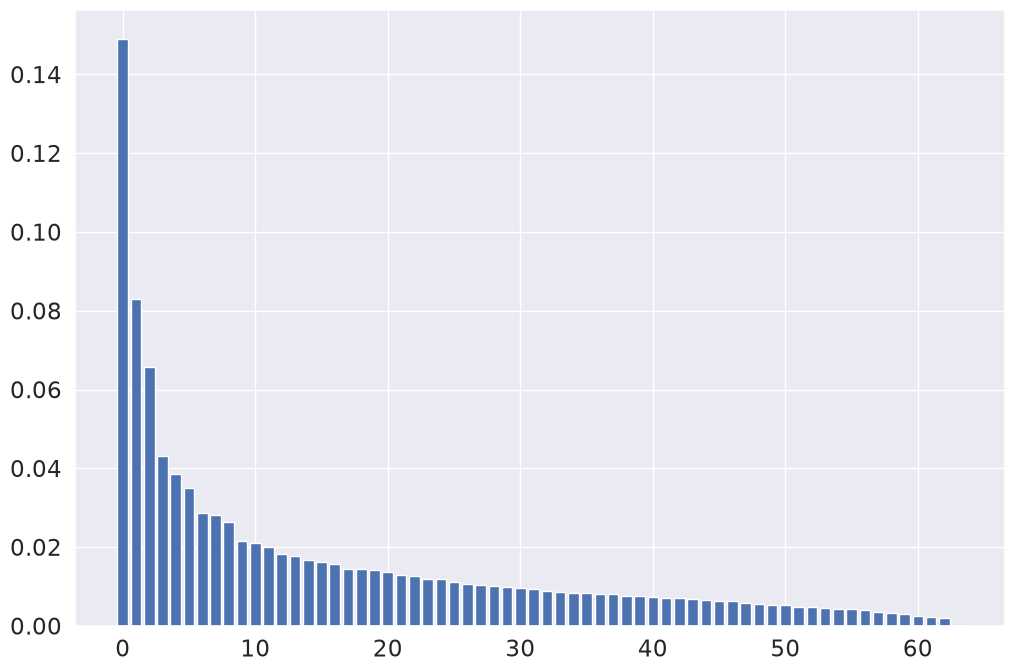

In [15]:
plt.bar(range(0,pca.n_components_), pca.explained_variance_ratio_)

In [16]:
# Compléter cette cellule (affichage) ~ 1 ligne de code

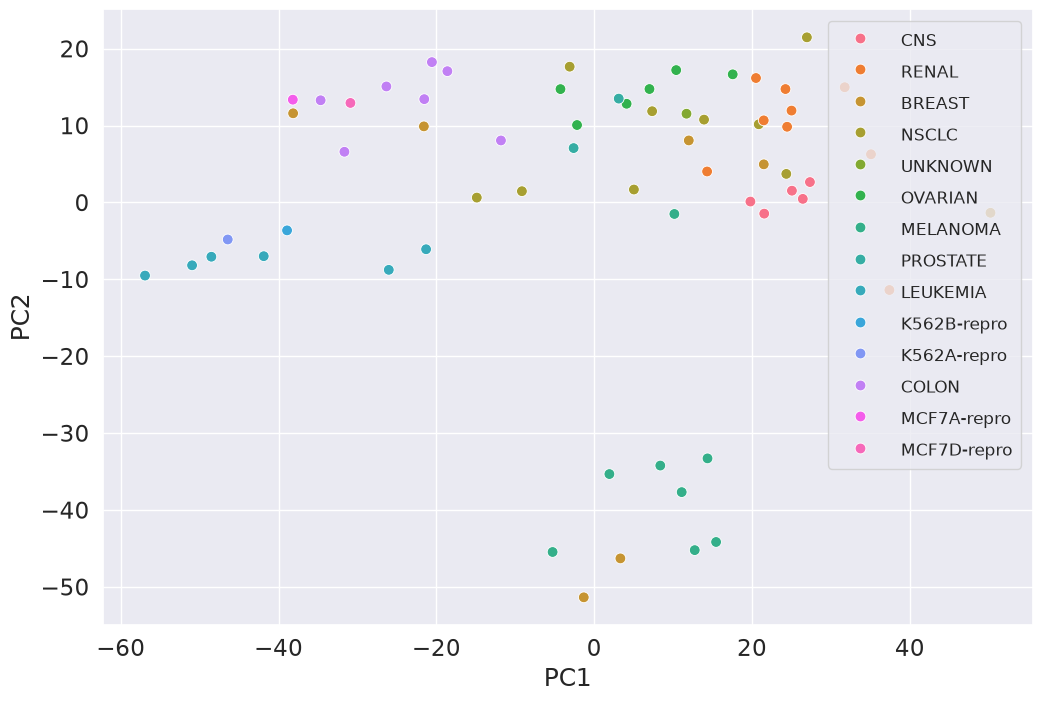

In [17]:
ax = sns.scatterplot(x=nci60_pca[:,0], y=nci60_pca[:,1], hue=nci60_labels['x'], s=60)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(loc='upper right')
_ = plt.setp(ax.get_legend().get_texts(), fontsize='12')

## 3 - Regroupement hiérarchique

Nous effectuons maintenant le regroupement hiérarchique à l'aide des 4 méthodes de lien vus en cours: Ward, Complete, Average et Single. La distance euclidienne est utilisée comme mesure de dissimilarité. Pour chaque lien, afficher le dendrogramme correspondant (voir `helpers.py`)

**Exercice 3-1 - Linkage par défaut (Ward)**

In [ ]:
# Compléter cette cellule ~ 2 lignes de code

In [18]:
from sklearn.cluster import AgglomerativeClustering

clust_ward = AgglomerativeClustering(distance_threshold=0, n_clusters=None).fit(nci60)

In [19]:
from helpers import plot_dendrogram

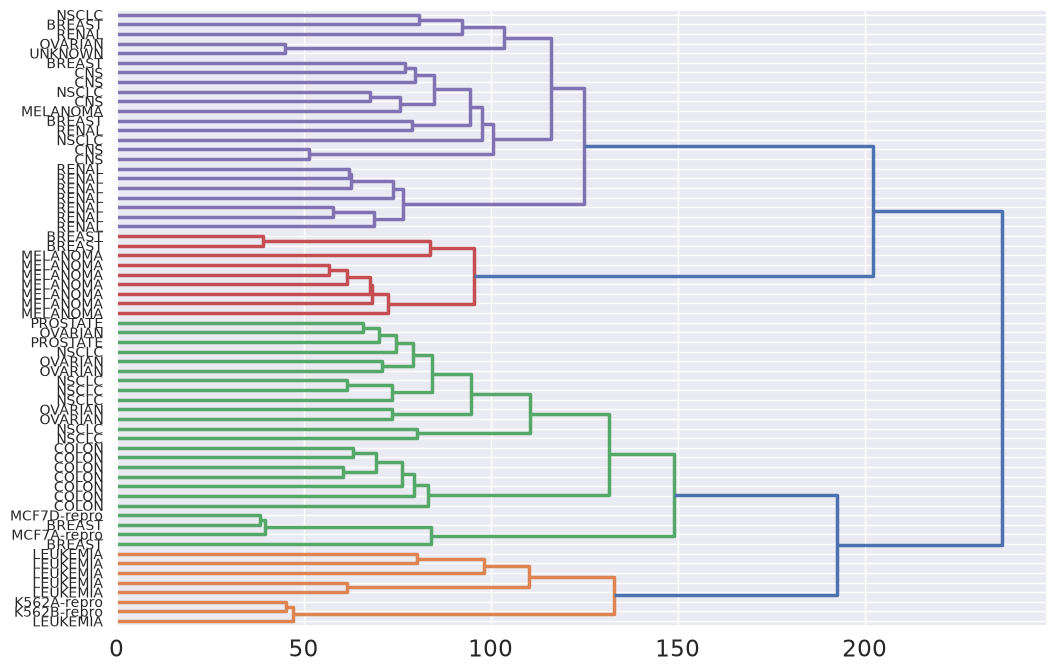

In [20]:
plot_dendrogram(clust_ward,orientation='right', labels=nci60_labels['x'].values, leaf_font_size=10)

**Exercice 3-2 - Linkage Complete**

In [21]:
# Compléter cette cellule ~ 2 lignes de code

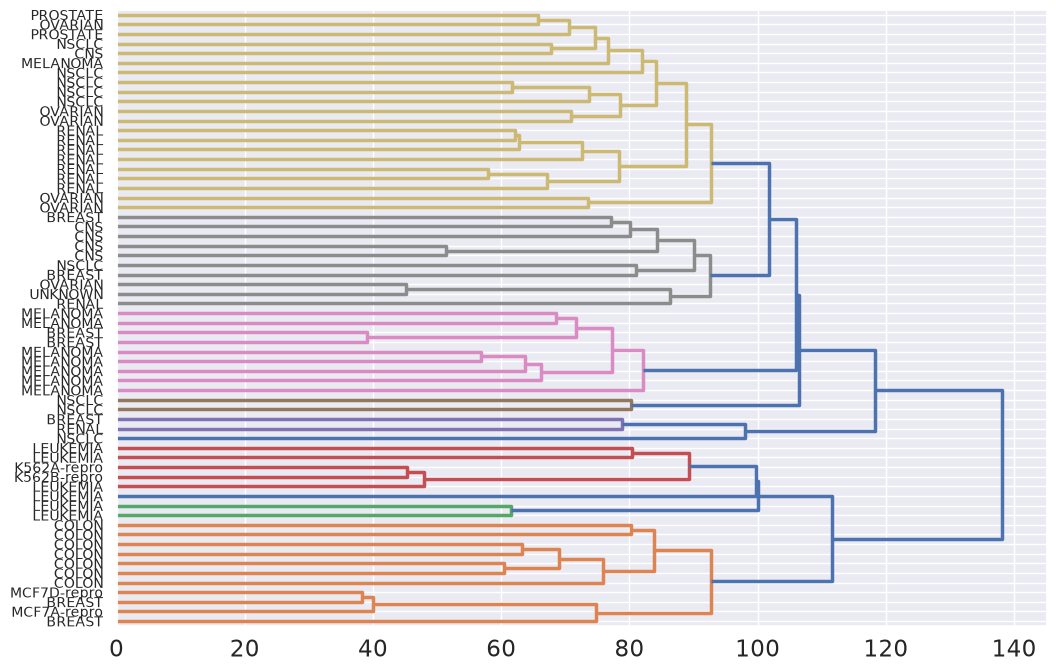

In [23]:
clust_complete = AgglomerativeClustering(distance_threshold=0, n_clusters=None, linkage='complete').fit(nci60)
plot_dendrogram(clust_complete, orientation='right', truncate_mode='level', labels=nci60_labels['x'].values, leaf_font_size=10)

**Exercice 3-3 - Linkage average**

In [24]:
# Compléter cette cellule ~ 2 lignes de code

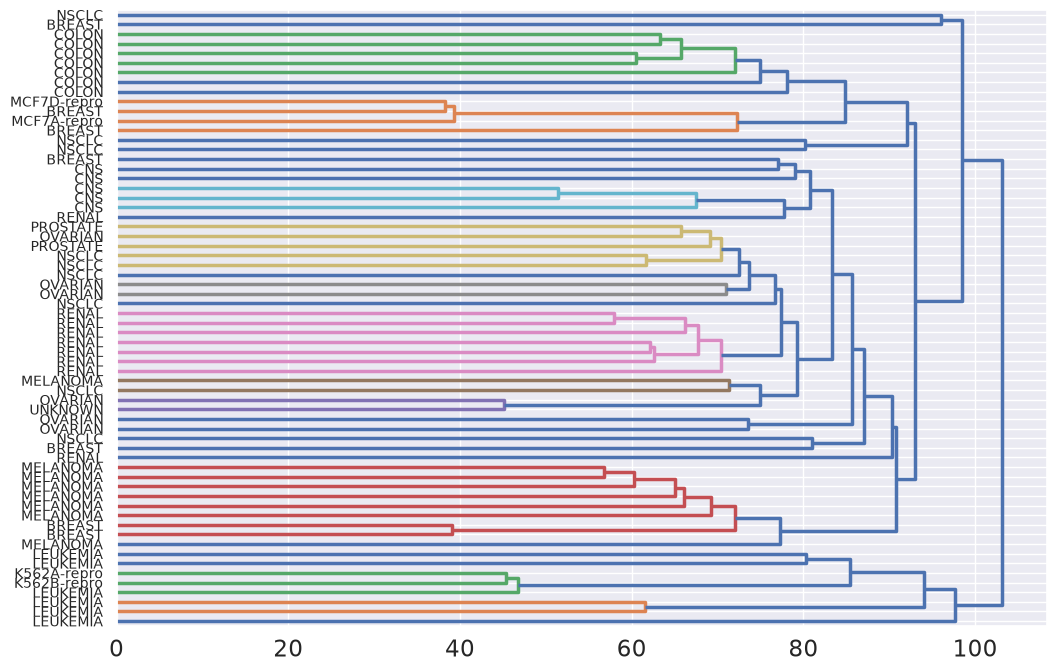

In [25]:
clust_average = AgglomerativeClustering(distance_threshold=0, n_clusters=None, linkage='average').fit(nci60)
plot_dendrogram(clust_average, orientation='right', truncate_mode='level', labels=nci60_labels['x'].values, leaf_font_size=10)

**Exercice 3-4 - Linkage Single**

In [26]:
# Compléter cette cellule ~ 2 lignes de code

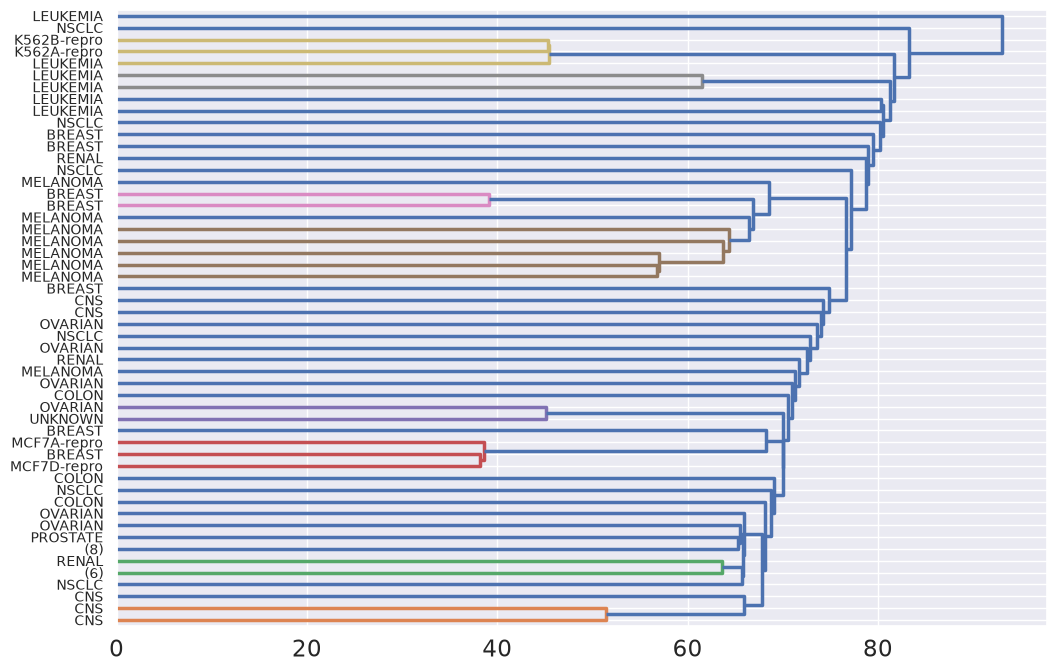

In [28]:
clust_single = AgglomerativeClustering(distance_threshold=0, n_clusters=None, linkage='single').fit(nci60)
plot_dendrogram(clust_single, orientation='right', truncate_mode='level', labels=nci60_labels['x'].values, leaf_font_size=10)

**Exercice 3-5 - Compte tenu des résultats précédents, choisir une méthode de lien et seuiller le dendrogramme à la hauteur "optimale"**

In [ ]:
# Compléter la cellule ~ 2 lignes de code

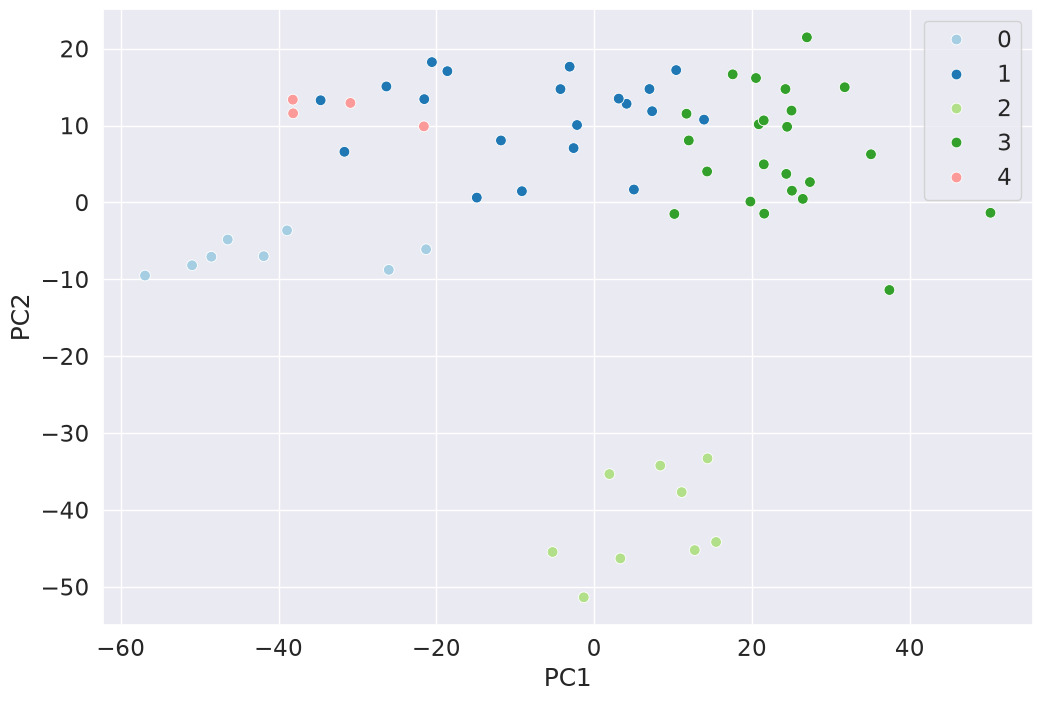

In [34]:
clust_complete = AgglomerativeClustering(distance_threshold=None, n_clusters=5).fit(nci60)

_ = sns.scatterplot(x=nci60_pca[:,0], y=nci60_pca[:,1], hue=clust_complete.labels_, s=60, palette="Paired")
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(loc='upper right')

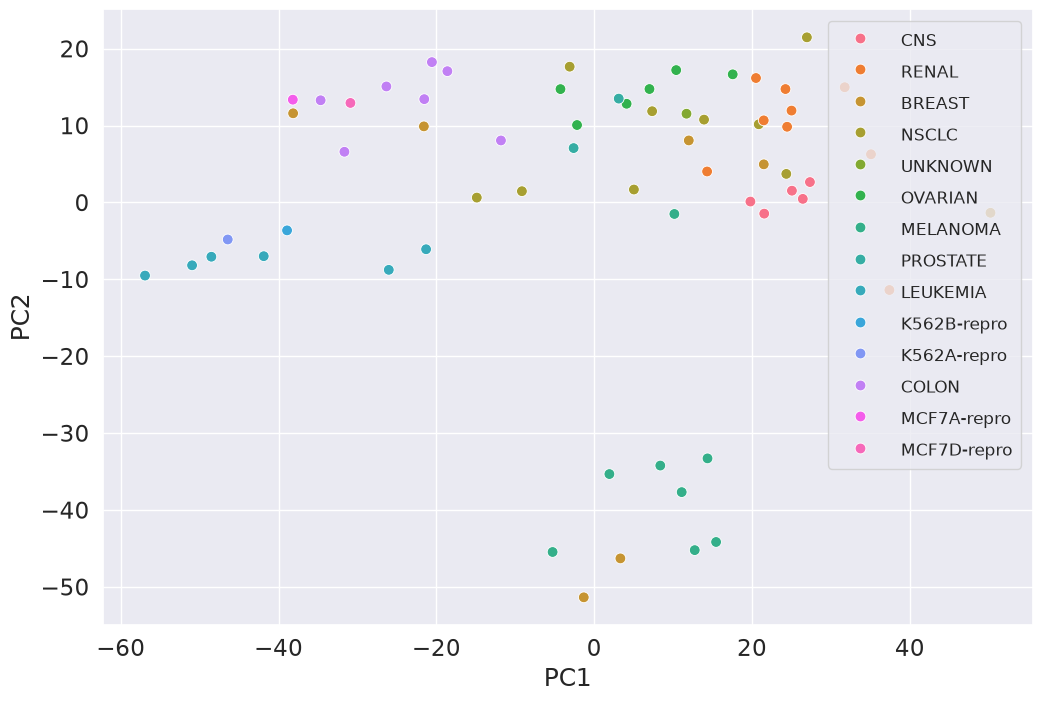

In [30]:
ax = sns.scatterplot(x=nci60_pca[:,0], y=nci60_pca[:,1], hue=nci60_labels['x'], s=60)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(loc='upper right')
_ = plt.setp(ax.get_legend().get_texts(), fontsize='12')

## 4 - Partitionnment K-moyennes

**Exercice 4 - Comparer les résultats précédents avec le partitionnement K-moyennes**

In [31]:
# Compléter la cellule ~ 5-10 lignes de code

In [32]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
nci60_scale = scaler.fit_transform(nci60)

from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=8, n_init=100, random_state=2020).fit(nci60_scale)

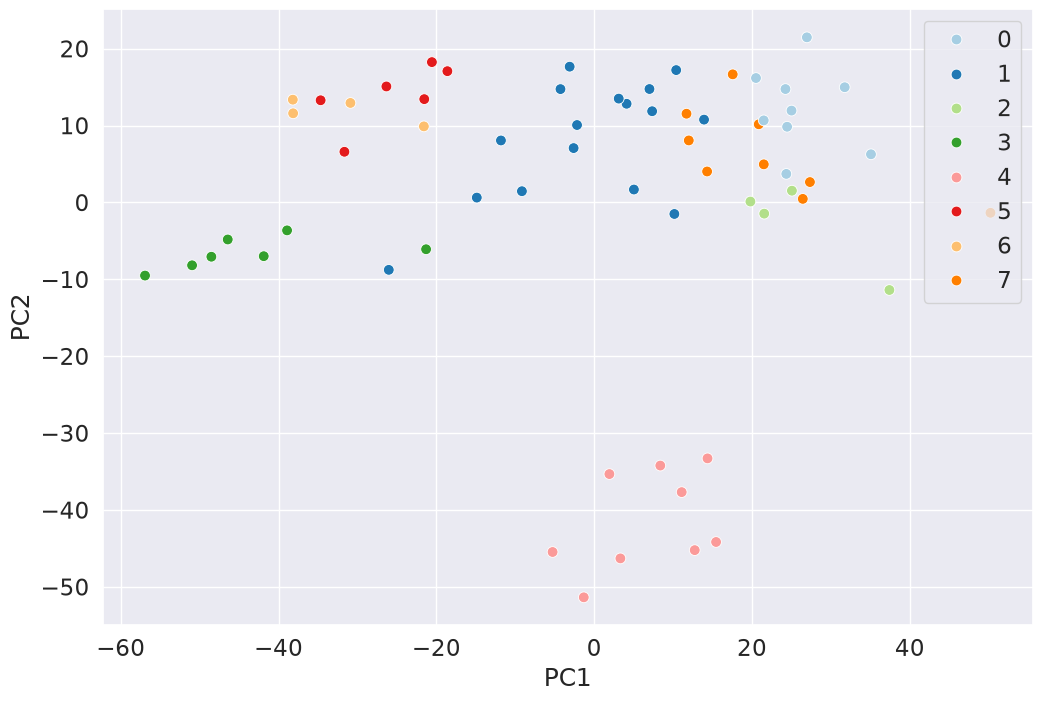

In [33]:
centroids = kmeans.cluster_centers_
c = kmeans.labels_

ax = sns.scatterplot(x=nci60_pca[:,0], y=nci60_pca[:,1], hue=c, s=60, palette="Paired")
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(loc='upper right')

## 5 - Débruitage des données par ACP (optionnel)

**Exercice 5 - Effectuer le partitionnement hiérarchique directement sur les premières composantes principales. Comparer les résultats obtenus avec ceux du jeu de données "complet"**

In [ ]:
# Compléter la cellule ~ X lignes de code

## 6 - Références

Cet atelier est grandement inspiré du Lab 3: NCI60 Data Example (Introduction to statistical learning)

### Fin de l'atelier